In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
os.chdir("Z:\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")
plants = pd.read_csv("plants_power.csv")
pop_dots = pd.read_csv("sample_pop_dots.csv")



In [3]:
import openmeteo_requests
import pandas as pd
import requests_cache
from retry_requests import retry
import time

os.chdir("C:\\Users\\DBT3KD\\Downloads")

# Configuration Open-Meteo
cache_session = requests_cache.CachedSession('.cache', expire_after=-1)
retry_session = retry(cache_session, retries=5, backoff_factor=0.2)
openmeteo = openmeteo_requests.Client(session=retry_session)

# Période d'intérêt
start_date = "2015-01-01"
end_date = "2023-12-31"



In [4]:
def download_temp(df):
	all_data = []

	# Boucle sur les points
	for idx, row in df.iterrows():
		lat = row["latitude"]
		lon = row["longitude"]
		
		params = {
			"latitude": lat,
			"longitude": lon,
			"start_date": start_date,
			"end_date": end_date,
			"hourly": ["temperature_2m", "relative_humidity_2m", "precipitation"]
		} 
		# ... à insérer dans ta boucle sur les points
		success = False
		while not success:
			try:
				responses = openmeteo.weather_api("https://archive-api.open-meteo.com/v1/archive", params=params)
				response = responses[0]

				hourly = response.Hourly()
				time_index = pd.date_range(
					start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
					end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
					freq=pd.Timedelta(seconds=hourly.Interval()),
					inclusive="left"
				)

				data = {
					"latitude": lat,
					"longitude": lon,
					"date": time_index,
					"temperature_2m": hourly.Variables(0).ValuesAsNumpy(),
					"relative_humidity_2m": hourly.Variables(1).ValuesAsNumpy(),
					"precipitation": hourly.Variables(2).ValuesAsNumpy()
				}

				df_point = pd.DataFrame(data)
				all_data.append(df_point)

				print(f"✅ Fini pour point {idx+1}/{len(df)} ({lat}, {lon})")

				time.sleep(5)  # Facultatif : pour réduire la pression sur l'API

				success = True  # Sortie de boucle si réussite

			except Exception as e:
				# Gérer l'erreur de quota (limite API)
				if hasattr(e, 'args') and len(e.args) > 0 and 'request limit exceeded' in str(e.args[0]).lower():
					print(f"⏳ Limite de requêtes atteinte pour ({lat}, {lon}). Attente de 60 secondes...")
					time.sleep(60)
				else:
					print(f"⚠️ Échec pour le point {idx+1}/{len(df)} ({lat}, {lon}): {e}")
					success = True  # Ne pas boucler indéfiniment pour d'autres types d'erreurs
	return(all_data)




In [10]:
all_pop_dots = download_temp(pop_dots)
full_pop = pd.concat(all_pop_dots, ignore_index=True)
full_pop.head(5)

✅ Fini pour point 1/100 (40.5483333720513, -1.6541666456365751)
✅ Fini pour point 2/100 (39.4216667099178, -0.3866666507274274)
✅ Fini pour point 3/100 (43.35500002742528, -4.059166635977011)
✅ Fini pour point 4/100 (40.9183333705626, -4.260833301833694)
✅ Fini pour point 5/100 (37.965000049112064, -6.180833294122108)
✅ Fini pour point 6/100 (40.296666706397225, -3.4333333051573067)
✅ Fini pour point 7/100 (42.1000000324748, -1.8033333117041224)
✅ Fini pour point 8/100 (39.279166710491154, -2.5924999752011395)
✅ Fini pour point 9/100 (36.61750005453376, -5.343333297485884)
✅ Fini pour point 10/100 (40.40166670597476, -3.624166637724168)
✅ Fini pour point 11/100 (37.77500004987654, -1.4508333131199225)
✅ Fini pour point 12/100 (37.22333338542951, -4.778333299755181)
✅ Fini pour point 13/100 (40.30166670637711, -3.8116666369710823)
✅ Fini pour point 14/100 (37.804166716425854, -1.778333311804534)
✅ Fini pour point 15/100 (40.47750003900297, -3.398333305297882)
✅ Fini pour point 16/100 (3

,latitude,longitude,date,temperature_2m,relative_humidity_2m,precipitation
0,40.548333,-1.654167,2015-01-01 00:00:00+00:00,-1.788,32.263115,0.0
1,40.548333,-1.654167,2015-01-01 01:00:00+00:00,-2.588,33.103199,0.0
2,40.548333,-1.654167,2015-01-01 02:00:00+00:00,-3.288,32.745255,0.0
3,40.548333,-1.654167,2015-01-01 03:00:00+00:00,-3.288,30.736574,0.0
4,40.548333,-1.654167,2015-01-01 04:00:00+00:00,-2.938,28.217499,0.0


In [51]:

all_plants = download_temp(plants)

# Concaténer les résultats
full_plants = pd.concat(all_plants, ignore_index=True)
full_plants.head(5)


✅ Fini pour point 1/83 (41.2, 0.5694444444444444)
✅ Fini pour point 2/83 (39.80805555555556, -5.696944444444445)
✅ Fini pour point 3/83 (41.41943888888888, 2.2297194444444446)
✅ Fini pour point 4/83 (39.95583333333334, 0.0013888888888888)
✅ Fini pour point 5/83 (36.6725, -5.816111111111111)
✅ Fini pour point 6/83 (39.24388888888889, -0.9319444444444444)
✅ Fini pour point 7/83 (37.57306111111112, -0.9391694444444444)
✅ Fini pour point 8/83 (39.64277777777778, -0.2327777777777777)
✅ Fini pour point 9/83 (37.18360833333333, -6.886972222222222)
✅ Fini pour point 10/83 (37.57056111111111, -0.9458305555555556)
✅ Fini pour point 11/83 (39.21666666666667, -1.05)
✅ Fini pour point 12/83 (40.95138888888889, 0.8666666666666667)
✅ Fini pour point 13/83 (40.70138888888889, -2.6222222222222222)
✅ Fini pour point 14/83 (39.73, -6.884722222222222)
✅ Fini pour point 15/83 (43.55306111111111, -5.723061111111111)
✅ Fini pour point 16/83 (41.336669444444446, 2.1591694444444443)
✅ Fini pour point 17/83 (43

,latitude,longitude,date,temperature_2m,relative_humidity_2m,precipitation
0,41.2,0.569444,2015-01-01 00:00:00+00:00,3.6185,54.416866,0.0
1,41.2,0.569444,2015-01-01 01:00:00+00:00,3.9685,49.034180,0.0
2,41.2,0.569444,2015-01-01 02:00:00+00:00,3.8185,47.155785,0.0
3,41.2,0.569444,2015-01-01 03:00:00+00:00,3.1185,51.273186,0.0
4,41.2,0.569444,2015-01-01 04:00:00+00:00,2.2685,59.648811,0.0


In [ ]:
os.chdir("Z:\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")
full_plants.to_parquet("temperature_plants.parquet", index=False)
full_pop.to_parquet("temperature_pop.parquet", index=False)



Pour valider notre démarche, on fait rapidement une carte de champ de température pour une date donnée, en faisant une petite animation durant une journée

In [ ]:
os.chdir("Z:\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")
full_plants = pd.read_parquet("temperature_plants.parquet")
full_pop = pd.read_parquet("temperature_pop.parquet")


In [9]:
# Filtrer les données pour ne garder que celles du 2020-01-01
full_pop['date'] = pd.to_datetime(full_pop['date'])  # S'assurer que la colonne 'date' est bien au format datetime
full_pop_2020_01_01 = full_pop[full_pop['date'].dt.date == pd.to_datetime('2020-01-01').date()]
full_pop_2020_01_01

,latitude,longitude,date,temperature_2m,relative_humidity_2m,precipitation
43824,40.548333,-1.654167,2020-01-01 00:00:00+00:00,2.0505,38.020584,0.0
43825,40.548333,-1.654167,2020-01-01 01:00:00+00:00,1.9005,36.930397,0.0
43826,40.548333,-1.654167,2020-01-01 02:00:00+00:00,1.8505,38.110149,0.0
43827,40.548333,-1.654167,2020-01-01 03:00:00+00:00,1.8005,39.637230,0.0
43828,40.548333,-1.654167,2020-01-01 04:00:00+00:00,1.6005,40.527870,0.0
...,...,...,...,...,...,...
7617091,41.742500,0.990833,2020-01-01 19:00:00+00:00,2.1860,96.839691,0.0
7617092,41.742500,0.990833,2020-01-01 20:00:00+00:00,1.9360,98.581444,0.0
7617093,41.742500,0.990833,2020-01-01 21:00:00+00:00,1.8360,99.643379,0.0
7617094,41.742500,0.990833,2020-01-01 22:00:00+00:00,1.4360,99.285583,0.0


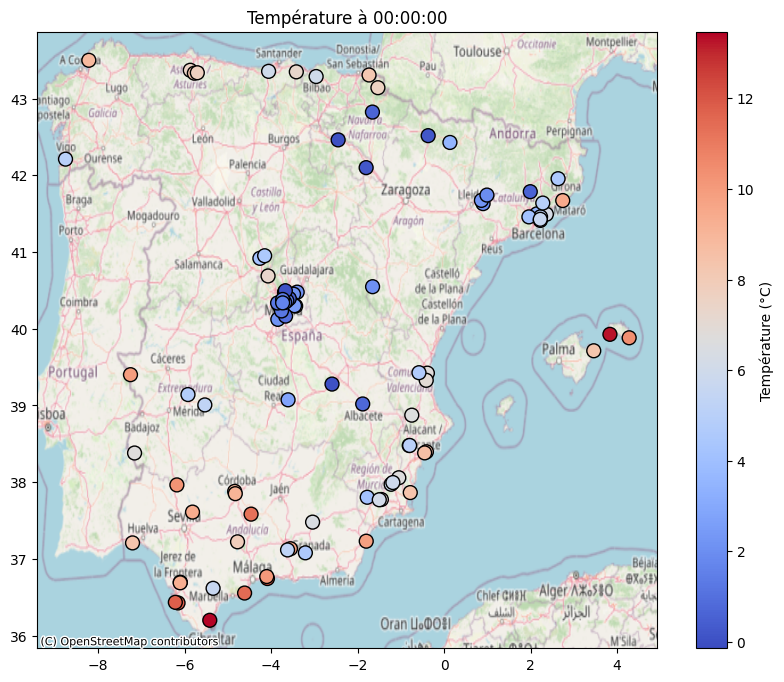

In [53]:
import contextily as ctx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import matplotlib.colors as mcolors
# Get the first frame's data
first_frame = 0
current_time = full_pop_2020_01_01['date'].iloc[first_frame]
temp_data = full_pop_2020_01_01[full_pop_2020_01_01['date'] == current_time]

# Create a figure and axes for the first frame
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the data for the first frame
scat = ax.scatter(temp_data['longitude'], temp_data['latitude'], c=temp_data['temperature_2m'], cmap='coolwarm', s=100, edgecolors='k')

# Ajouter le fond de carte
ctx.add_basemap(ax, crs='EPSG:4326', source=ctx.providers.OpenStreetMap.Mapnik)


# Add a color bar
cbar = fig.colorbar(scat, ax=ax, orientation='vertical')
cbar.set_label('Température (°C)')

# Update the title with the current time
ax.set_title(f"Température à {current_time.strftime('%H:%M:%S')}")

# Show the plot
plt.show()


C:\Users\DBT3KD\AppData\Roaming\Python\Python312\site-packages\matplotlib\animation.py:872: UserWarning: Animation was deleted without rendering anything. This is most likely not intended. To prevent deletion, assign the Animation to a variable, e.g. `anim`, that exists until you output the Animation using `plt.show()` or `anim.save()`.
  warnings.warn(


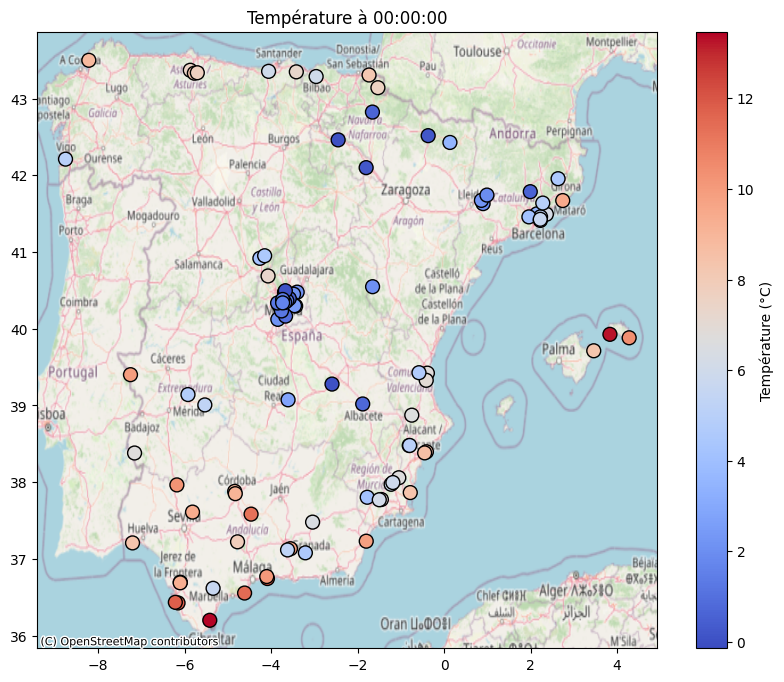

In [67]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import contextily as ctx
import pandas as pd
import numpy as np

# Unique timestamps
timestamps = full_pop_2020_01_01['date'].unique()

# Set up the figure and axis
fig, ax = plt.subplots(figsize=(10, 8))

# Initial frame (first timestamp)
initial_time = timestamps[0]
initial_data = full_pop_2020_01_01[full_pop_2020_01_01['date'] == initial_time]

# Create the scatter plot (with dummy data first)
scat = ax.scatter(
    initial_data['longitude'],
    initial_data['latitude'],
    c=initial_data['temperature_2m'],
    cmap='coolwarm',
    s=100,
    edgecolors='k'
)

# Add the basemap (will stay static)
ctx.add_basemap(ax, crs='EPSG:4326', source=ctx.providers.OpenStreetMap.Mapnik)

# Add color bar
cbar = fig.colorbar(scat, ax=ax, orientation='vertical')
cbar.set_label('Température (°C)')

# Title setup
title = ax.set_title(f"Température à {initial_time.strftime('%H:%M:%S')}")

# ---- Animation update function ---- #
def update(frame_idx):
    current_time = timestamps[frame_idx]
    temp_data = full_pop_2020_01_01[full_pop_2020_01_01['date'] == current_time]

    scat.set_offsets(np.c_[temp_data['longitude'], temp_data['latitude']])
    scat.set_array(temp_data['temperature_2m'].values)

    title.set_text(f"Température à {current_time.strftime('%H:%M:%S')}")

    return scat, title

# ---- Create animation ---- #
ani = animation.FuncAnimation(
    fig, update, frames=len(timestamps), interval=500, blit=False
)

plt.close()  # Prevent duplicate display in Jupyter


In [68]:
from IPython.display import HTML
HTML(ani.to_jshtml())


In [73]:
ani.save("temperature_animation.gif", writer='pillow', fps=2)
